Marina Maldonado Montemayor 2276151

Manuel Benavides Herrera 2276359

Ximena Maria Mejia Zuñiga 2208778

Cesar Said Herrera Velazquez 2204661

Valeria Sarahí Reyes Mendoza 2164878

Lógica: Se utilizaron las herramientas vistas en clase para entrenar un árbol de decisión que haga predicciones sobre los pacientes que padecen o no diabetes

In [8]:
# 1. Carga del Conjunto de Datos Público

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

# URL pública del dataset de Diabetes
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columnas = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df = pd.read_csv(url, header=None, names=columnas)
print("Primeras filas del dataset original:")
df.head()

Primeras filas del dataset original:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# 2. Análisis Exploratorio y Visualización

df.describe()
#El describe es para hacer un resumen estadistico completo

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


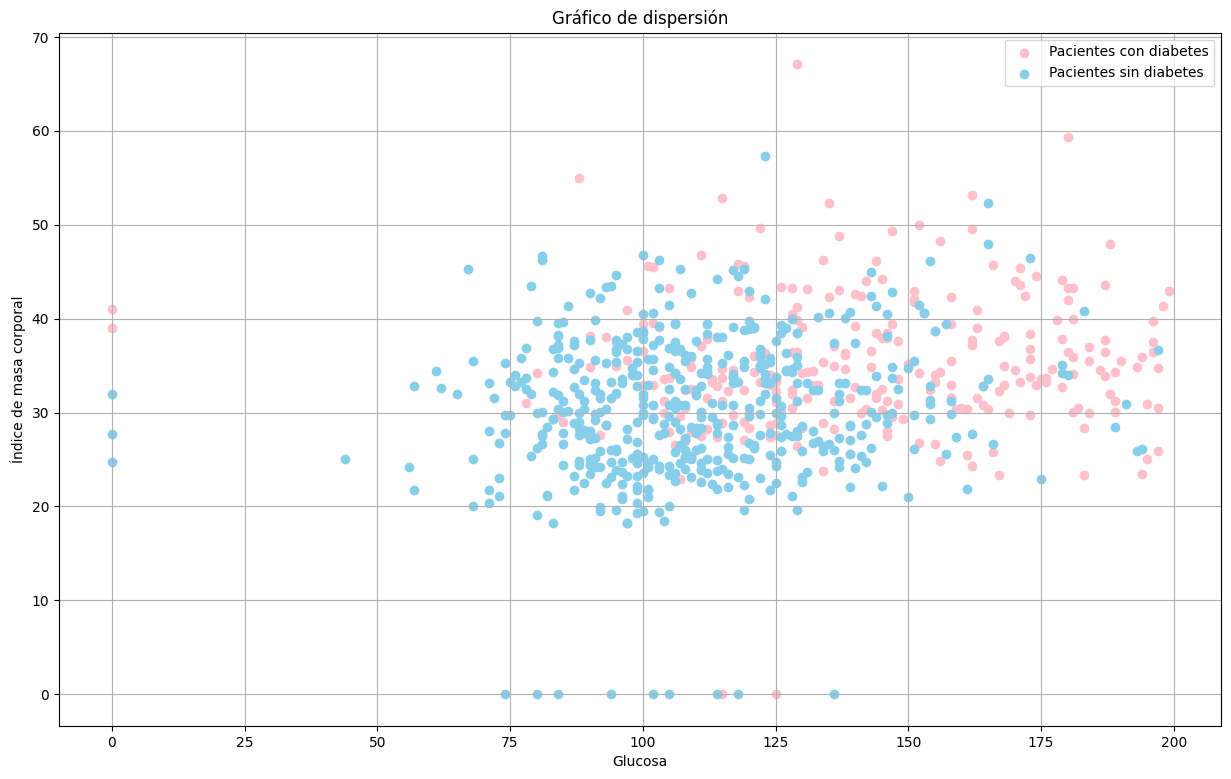

In [4]:
diabetes = df[df['Outcome'] == 1]
no_diabetes = df[df['Outcome'] == 0] #el df aparece 2 veces porque sirve como un filtro para la condición
plt.figure(figsize=(15, 9)) #se pone antes del plt.scatter para que se aplique al gráfico

plt.scatter(diabetes['Glucose'], diabetes['BMI'], color='pink', label="Pacientes con diabetes")
plt.scatter(no_diabetes['Glucose'], no_diabetes['BMI'], color='skyblue', label="Pacientes sin diabetes")
plt.title('Gráfico de dispersión')
plt.xlabel('Glucosa')
plt.ylabel('Índice de masa corporal')
plt.legend()
plt.grid()
plt.show()

In [5]:
# 3. Limpieza y Preprocesamiento de Datos

nulos = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI'] #Se guardan las columnas en una variable para facilitar la visualización del código
df[nulos] = df[nulos].replace(0, np.nan)  #Aqui se reemplazan los valores que son igual a 0 a valores nulos
df[nulos] = df[nulos].fillna(df[nulos].mean()) #Se rellenan los valores nulos con las medias correspondientes

#Calculo de cuartiles
Q1, Q3 = np.percentile(df['Insulin'], [25, 75])
IQR = Q3 - Q1
limite_inf = Q1 - (1.5 * IQR)
limite_sup = Q3 + (1.5 * IQR)

#Conserva datos dentro de los rangos
df = df[df['Insulin'].between(limite_inf, limite_sup)]

In [6]:
# 4. Entrenamiento y Evaluación del Árbol de Decisión

X = df.drop(columns=['Outcome']) #columns=['Outcome'] se agrega para eliminar la columna completa
y = df['Outcome']

#Partición del conjunto
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
model = DecisionTreeClassifier()
model.fit(X_train, y_train)

#Exactitud del entrenamiento del modelo
train_accuracy = model.score(X_train, y_train)
print('Exactitud del modelo:', train_accuracy)

#Prueba del modelo
y_pred = model.predict(X_test)
y_pred

#Predicciones
print('\n Predicción 1:')
print(y_pred[1])
print(y_test.iloc[1]) #iloc se utiliza para seleccionar datos basándose en su posición numérica entera

print('\n Predicción 2:')
print(y_pred[30])
print(y_test.iloc[30])

print('\n Predicción 3:')
print(y_pred[-1]) #Imprime la última prediccion
print(y_test.iloc[-1])

#Reporte de clasificación detallado
reporte = classification_report(y_test, y_pred)
print(reporte)

Exactitud del modelo: 1.0

 Predicción 1:
0
0

 Predicción 2:
0
0

 Predicción 3:
1
1
              precision    recall  f1-score   support

           0       0.81      0.79      0.80        95
           1       0.66      0.68      0.67        56

    accuracy                           0.75       151
   macro avg       0.73      0.73      0.73       151
weighted avg       0.75      0.75      0.75       151



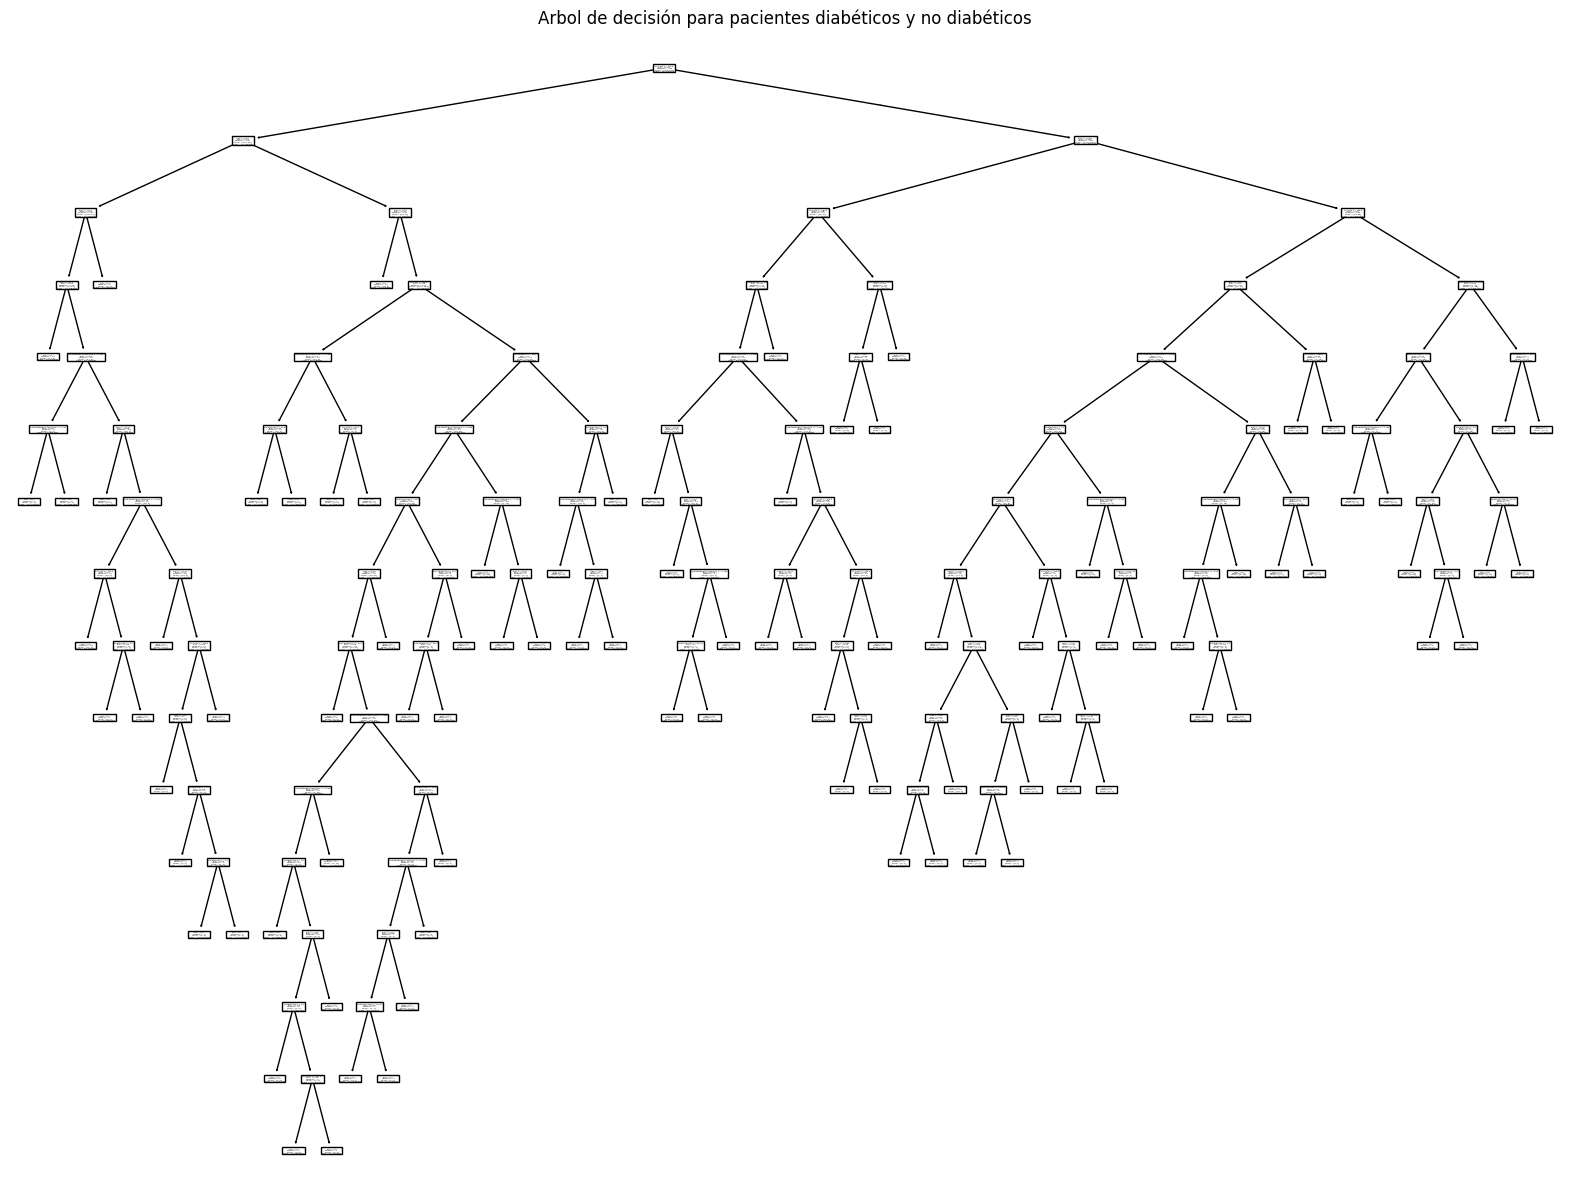

In [7]:
#Visualización de la Estructura

plt.figure(figsize=(20, 15))
plot_tree(model, feature_names=X.columns, class_names=['Sin diabetes', 'Con diabetes'])
plt.title('Arbol de decisión para pacientes diabéticos y no diabéticos')
plt.show()